<a href="https://colab.research.google.com/github/iqrabatool1/AI-Powered-Sales-Forecasting-Automated-Insight-Reporting-System/blob/main/final_year_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower().endswith((".png", ".jpg", ".jpeg")):
            print(os.path.join(root, file))

/content/00e4ddff966a.png
/content/00cc2b75cddd.png
/content/00b74780d31d.png
/content/00a8624548a9.png
/content/000c1434d8d7.png
/content/00cb6555d108.png


Total images found: 6


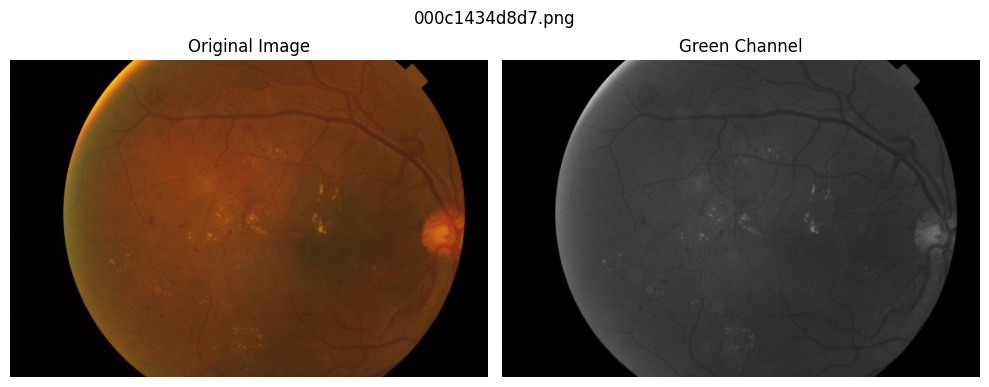

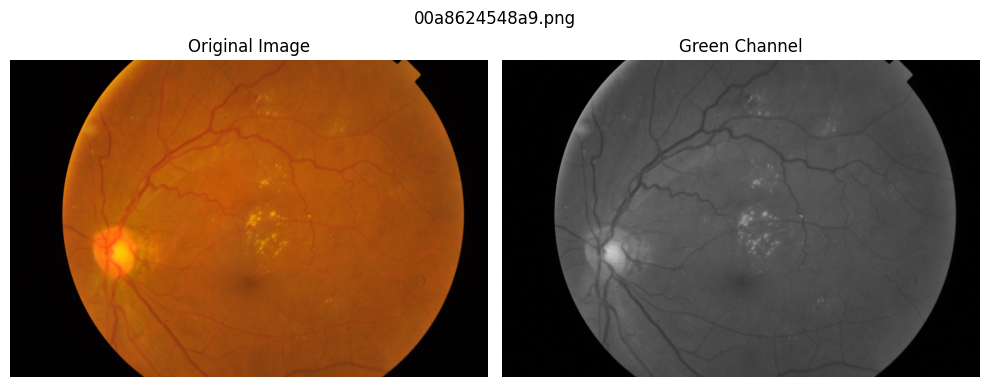

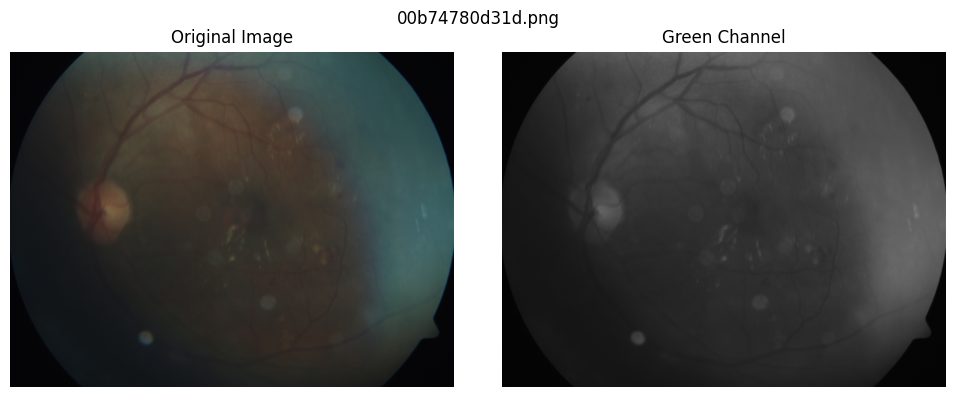

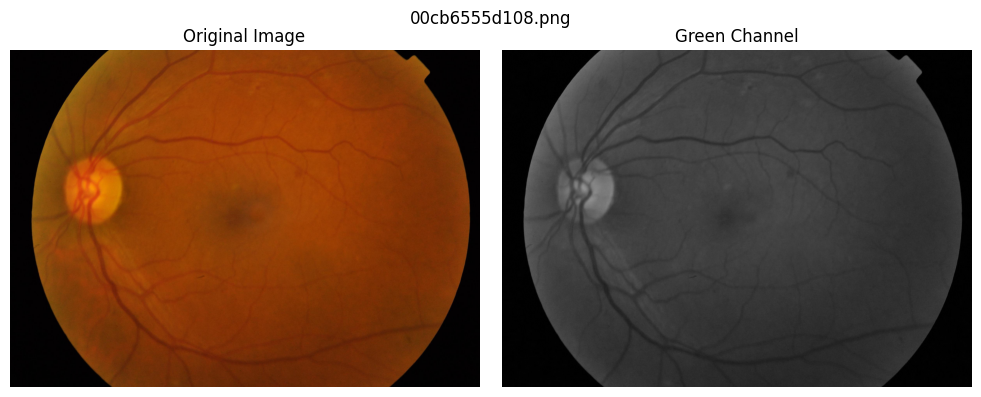

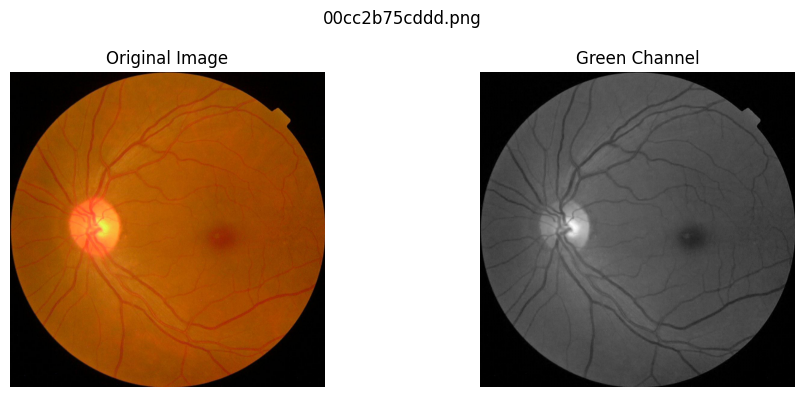

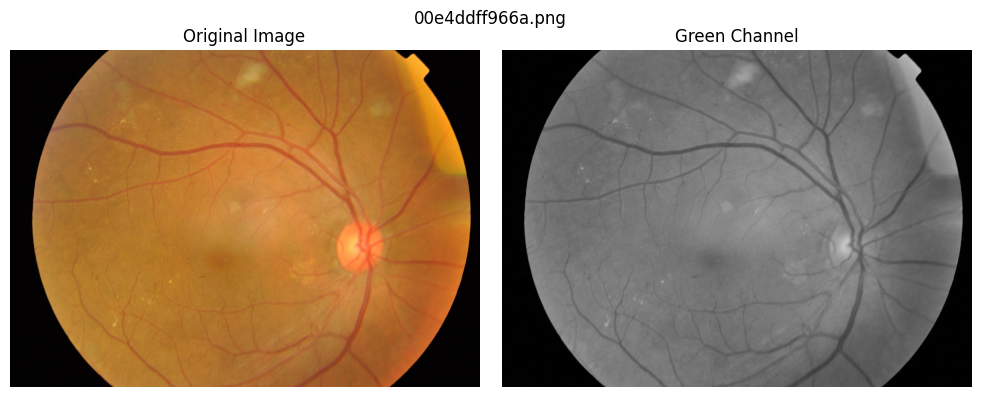

Processing completed!


In [5]:

import cv2
import os
import matplotlib.pyplot as plt

# Folder containing your retinal images
input_folder = "/content"

# Folder to save processed images
output_folder = "/content/green_channel_results"
os.makedirs(output_folder, exist_ok=True)

# Select only image files
image_files = [
    f for f in os.listdir(input_folder)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

print("Total images found:", len(image_files))

for filename in sorted(image_files):

    # Read original image
    path = os.path.join(input_folder, filename)
    image = cv2.imread(path)

    if image is None:
        print("Could not read:", filename)
        continue

    # Extract green channel
    green_channel = image[:, :, 1]

    # Save processed image
    save_path = os.path.join(output_folder, filename)
    cv2.imwrite(save_path, green_channel)

    # Show comparison
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(green_channel, cmap="gray",
               vmin=0, vmax=255)
    plt.title("Green Channel")
    plt.axis("off")

    plt.suptitle(filename)
    plt.tight_layout()
    plt.show()

print("Processing completed!")


Total images found: 6


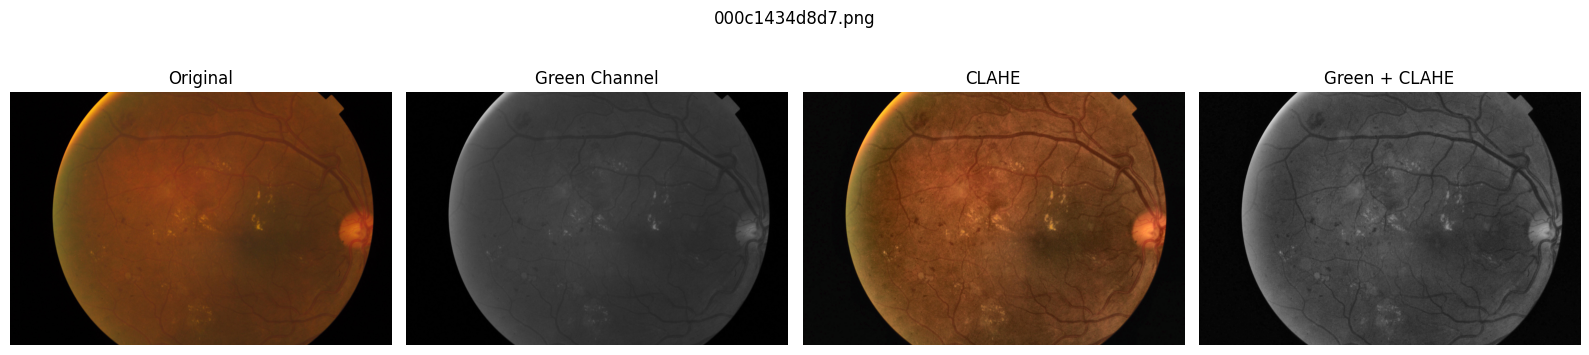

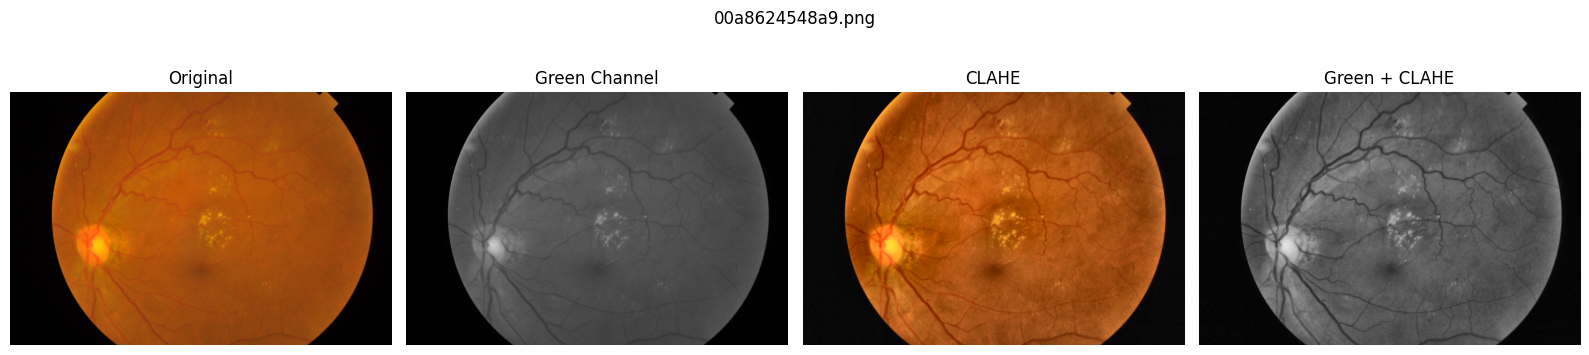

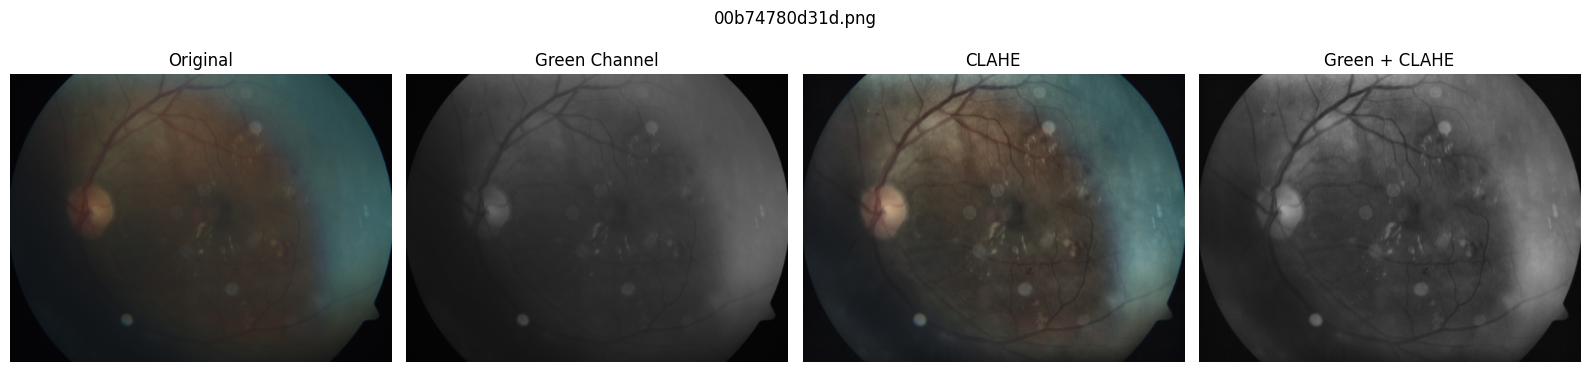

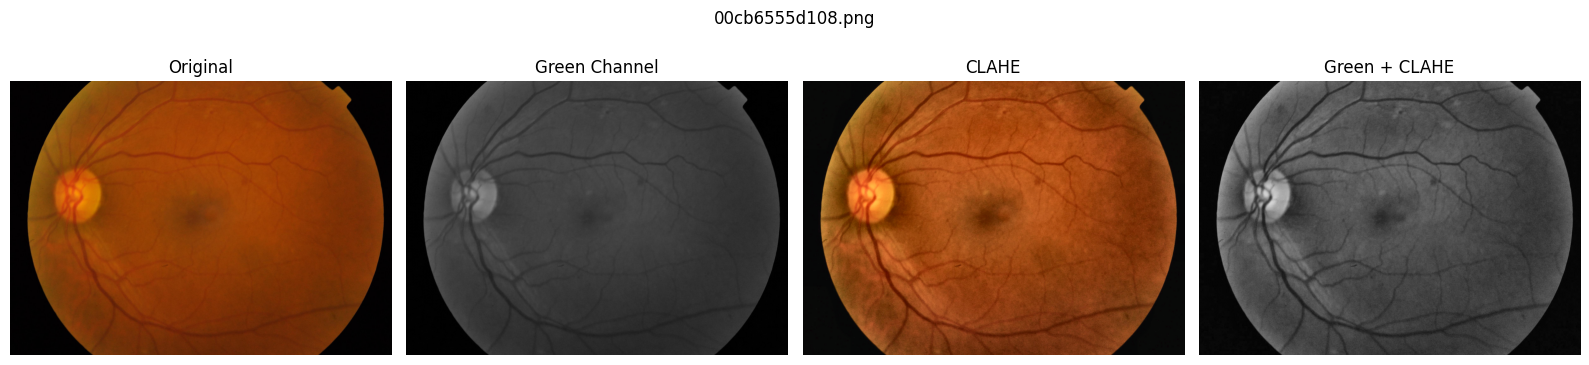

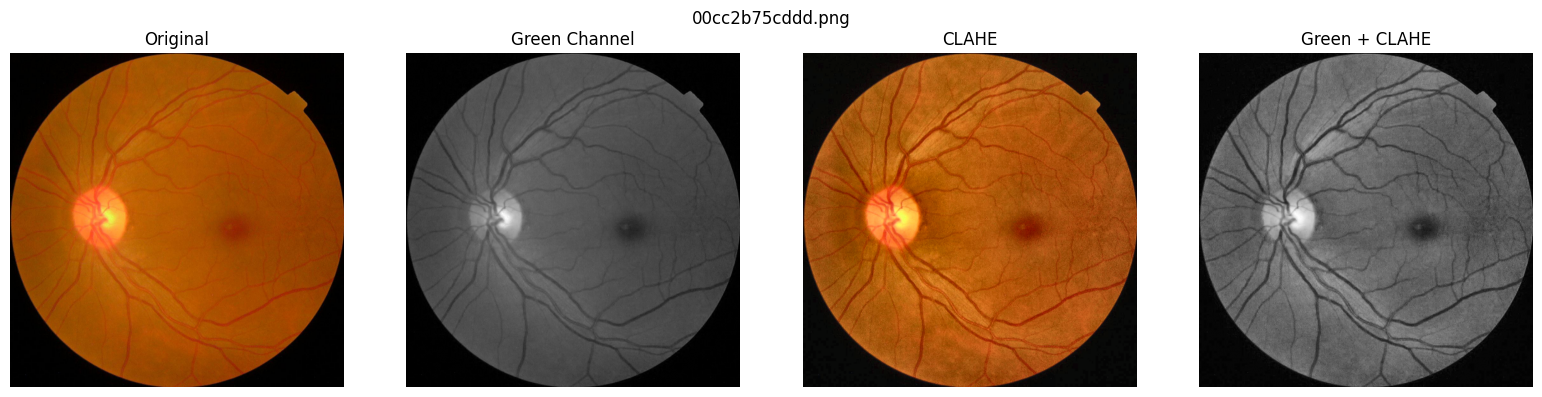

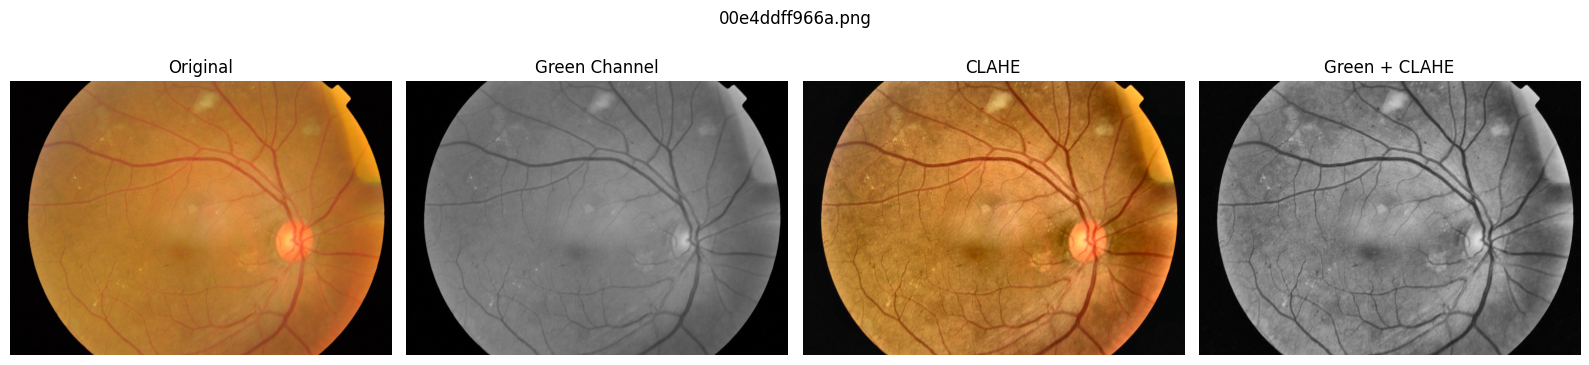

All preprocessing experiments completed!


In [6]:

import cv2
import os
import matplotlib.pyplot as plt

# Use the folder that contains your 6 original images
input_folder = "/content"

# Create folders for results
clahe_folder = "/content/clahe_results"
combined_folder = "/content/green_clahe_results"

os.makedirs(clahe_folder, exist_ok=True)
os.makedirs(combined_folder, exist_ok=True)

# Find image files
image_files = sorted([
    f for f in os.listdir(input_folder)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

print("Total images found:", len(image_files))

# Create CLAHE object
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

for filename in image_files:

    path = os.path.join(input_folder, filename)
    image = cv2.imread(path)

    if image is None:
        continue

    # Original RGB image
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Method 1: Green Channel
    green = image[:, :, 1]

    # Method 2: Color-preserving CLAHE
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    enhanced_l = clahe.apply(l)
    enhanced_lab = cv2.merge((enhanced_l, a, b))

    clahe_bgr = cv2.cvtColor(
        enhanced_lab, cv2.COLOR_LAB2BGR
    )
    clahe_rgb = cv2.cvtColor(
        clahe_bgr, cv2.COLOR_BGR2RGB
    )

    # Method 3: Green Channel + CLAHE
    green_clahe = clahe.apply(green)

    # Save processed images
    cv2.imwrite(
        os.path.join(clahe_folder, filename),
        clahe_bgr
    )

    cv2.imwrite(
        os.path.join(combined_folder, filename),
        green_clahe
    )

    # Display all four versions
    plt.figure(figsize=(16, 4))

    plt.subplot(1, 4, 1)
    plt.imshow(rgb)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 4, 2)
    plt.imshow(green, cmap="gray", vmin=0, vmax=255)
    plt.title("Green Channel")
    plt.axis("off")

    plt.subplot(1, 4, 3)
    plt.imshow(clahe_rgb)
    plt.title("CLAHE")
    plt.axis("off")

    plt.subplot(1, 4, 4)
    plt.imshow(green_clahe, cmap="gray",
               vmin=0, vmax=255)
    plt.title("Green + CLAHE")
    plt.axis("off")

    plt.suptitle(filename)
    plt.tight_layout()
    plt.show()

print("All preprocessing experiments completed!")
